# Ticha HTR — using the model

How to read a manuscript line with [`maclenn77/ticha-trocr-base`](https://huggingface.co/maclenn77/ticha-trocr-base), TrOCR base fine-tuned on Colonial Zapotec and Spanish manuscripts from [Ticha](https://ticha.haverford.edu/).

- **Input:** the image of **one text line**, cropped from a page (the model does not find lines on a page).
- **Output:** the line as text, as a diplomatic transcription: what is written, abbreviations not expanded.

The repository holds two models. The one at the root reads the line (left to right). The one in `r2l/` reads candidate lines backwards and is only used to rerank: decoding with 10 beams and reranking them with it is the best system (test CER 13.6%, against 14.1% for 10 beams alone).

Runs on a GPU, an Apple Silicon GPU (MPS) or a CPU (slower: a few seconds per line). No training is needed: the models and the dataset are downloaded from the Hugging Face Hub.

**Requirements:** from the repository root, `pip install -e '.[htr]' datasets jiwer` (the notebook imports `ticha` from `src/`, so an installed package is not required), or the **Python (ticha)** environment of [`environment.yml`](../../environment.yml), which has everything this notebook needs (see [`ENVIRONMENT.md`](../../ENVIRONMENT.md)).

In [1]:
import sys
from pathlib import Path

from datasets import load_dataset
from IPython.display import display
from jiwer import cer

# The kernel may start in the repo root (VS Code, the VM's Jupyter service) or in notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ticha').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from ticha.core.htr import RERANK_WEIGHT, LineReader, best_candidate, clean_text

reader = LineReader.from_pretrained('maclenn77/ticha-trocr-base')  # rerank=False skips the r2l model
print('device:', reader.device)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}



Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder_layerdrop": 0.0,
  "decoder_layers": 12,
  "decoder_start_token_id": 2,
  "dropout": 0.1,
  "eos_token_id": 2,
  "init_std": 0.02,
  "is_decoder": true,
  "layernorm_embedding": true,
  "max_position_embeddings": 512,
  "model_type": "trocr",
  "pad_token_id": 1,
  "scale_embedding": false,
  "transformers_version": "4.46.3",
  "use_cache": false,
  "use_learned_position_embeddings": true,
  "vocab_size": 50265
}



Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}



Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder_layerdrop": 0.0,
  "decoder_layers": 12,
  "decoder_start_token_id": 2,
  "dropout": 0.1,
  "eos_token_id": 2,
  "init_std": 0.02,
  "is_decoder": true,
  "layernorm_embedding": true,
  "max_position_embeddings": 512,
  "model_type": "trocr",
  "pad_token_id": 1,
  "scale_embedding": false,
  "transformers_version": "4.46.3",
  "use_cache": false,
  "use_learned_position_embeddings": true,
  "vocab_size": 50265
}



device: cuda


## 1. Some test lines

The test split of [`maclenn77/ticha-htr-lines`](https://huggingface.co/datasets/maclenn77/ticha-htr-lines), which the model never saw. Za687 is left out: the model was trained on dataset version 1.0, which has the same pages in train (Th687).

The transcriptions in the dataset still have the transcribers' notes: `[...]` and `(...)` for expansions, glosses and damage. `clean_text` (in `ticha.core.htr`) is the rule used in training and evaluation: it deletes expansions (`p[es]os` becomes `pos`) and drops lines with damage or illegible text, so the reference matches what is on the page.

In [2]:
test = load_dataset('maclenn77/ticha-htr-lines', 'original', split='test', revision='v1.1')
examples, seen = [], set()
for row in test:  # the first clean line from line 5 on, in each of 8 documents
    reference = clean_text(row['text'])
    if reference and row['doc_id'] not in seen and row['line'] >= 5:
        examples.append({**row, 'reference': reference})
        seen.add(row['doc_id'])
    if len(examples) == 8:
        break
print(len(examples), 'lines from', sorted(seen))

8 lines from ['Al684', 'Al707T', 'Ma733', 'Ri832', 'SDE693a', 'SDE725c', 'SDE726', 'Tv758']


## 2. One line, step by step

The processor resizes the line image to 384 × 384 pixels and normalizes it. `reader.candidates` runs beam search and returns the 10 best readings, best first, each with its token ids and two scores: the summed log-probability that the left-to-right model gives it, and the one the right-to-left model gives it read backwards.

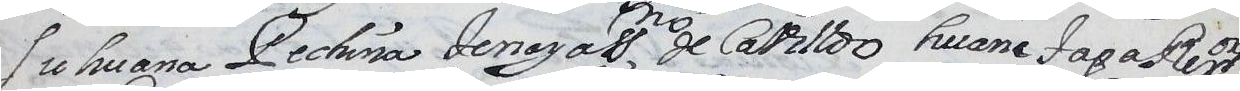

SDE693a, page 1, line 5 (Zapotec)
dataset text: luhuana Pechina teneya ss[criva]no de Cafilldo huane tapa Rex[id]ors
reference:    luhuana Pechina teneya ssno de Cafilldo huane tapa Rexors
model input:  (1, 3, 384, 384)


0: su huana Lachina tenaya q. de cavildo huane tapa Real
1: su huana Lachina tenaya q. de cavildo huane tapa Rosa
2: su huana Lachina tenaya q. de cavildo huane tapa Regr
3: su huana Bechina tenaya q. de cavildo huane tapa Regr
4: su huana Lachina tenaya q. de Castilla huane tapa Regr
5: su huana Lachina benaya q. de cavildo huane tapa Regr
6: su huana Lachina tenaya ssno de cavildo huane tapa Regr
7: su huana Bechina tenaya q. de Castilla huane tapa Regr
8: su huana Lachina tenaya ssno de Cavildo huane tapa Regr
9: su huana Lachina tenaya q. de cavildo huane tapa Rey


In [3]:
example = examples[0]
display(example['image'])
print(f"{example['doc_id']}, page {example['page']}, line {example['line']} ({example['language']})")
print('dataset text:', example['text'])
print('reference:   ', example['reference'])
print('model input: ', tuple(reader.pixel_values([example['image']]).shape))

candidates = reader.candidates([example['image']], beams=10)[0]
for k, c in enumerate(candidates):
    print(f'{k}: {c.text}')

## 3. Reranking with the right-to-left model

The combined score of each candidate is

`((1 − w) · log p_left-to-right + w · log p_right-to-left) / number of tokens`

with `w = 0.3`, the weight chosen on validation for 10 beams (`RERANK_WEIGHT`). The candidate with the best score is the reading.

The rerank lowers the CER on average (0.55 points on the test set), but it does not improve every line: on some it picks a candidate that reads worse than the first beam.

In [4]:
best = best_candidate(candidates, RERANK_WEIGHT)
for k, c in enumerate(candidates):
    print(f"{'>' if c is best else ' '} {k}: {c.score():7.3f}  (L2R {c.l2r:7.2f}, R2L {c.r2l:7.2f})  {c.text}")
print()
print('10 beams alone:', candidates[0].text, f'| CER {cer(example["reference"], candidates[0].text or " "):.1%}')
print('with rerank:   ', best.text, f'| CER {cer(example["reference"], best.text or " "):.1%}')

  0:  -1.402  (L2R  -25.13, R2L  -39.50)  su huana Lachina tenaya q. de cavildo huane tapa Real
  1:  -1.423  (L2R  -25.37, R2L  -40.41)  su huana Lachina tenaya q. de cavildo huane tapa Rosa
  2:  -1.433  (L2R  -27.02, R2L  -42.06)  su huana Lachina tenaya q. de cavildo huane tapa Regr
  3:  -1.514  (L2R  -28.00, R2L  -45.66)  su huana Bechina tenaya q. de cavildo huane tapa Regr
  4:  -1.544  (L2R  -28.07, R2L  -47.70)  su huana Lachina tenaya q. de Castilla huane tapa Regr
  5:  -1.525  (L2R  -28.08, R2L  -46.29)  su huana Lachina benaya q. de cavildo huane tapa Regr
  6:  -1.415  (L2R  -28.30, R2L  -37.75)  su huana Lachina tenaya ssno de cavildo huane tapa Regr
  7:  -1.606  (L2R  -28.52, R2L  -51.24)  su huana Bechina tenaya q. de Castilla huane tapa Regr
> 8:  -1.389  (L2R  -28.75, R2L  -34.75)  su huana Lachina tenaya ssno de Cavildo huane tapa Regr
  9:  -1.561  (L2R  -28.90, R2L  -47.00)  su huana Lachina tenaya q. de cavildo huane tapa Rey

10 beams alone: su huana Lachina t

## 4. Transcribing lines

`reader.transcribe` takes one image (a PIL image or a path) and returns its text, or a list of images and returns a list of texts. It reranks by default; `rerank=False` keeps the first beam.

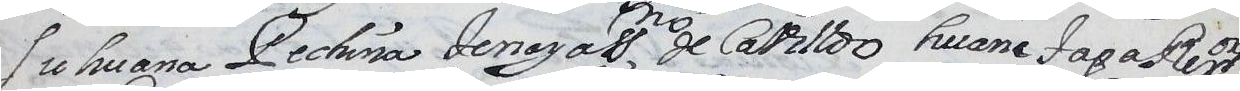

SDE693a (Zapotec)
  reference: luhuana Pechina teneya ssno de Cafilldo huane tapa Rexors
  model:     su huana Lachina tenaya ssno de Cavildo huane tapa Regr



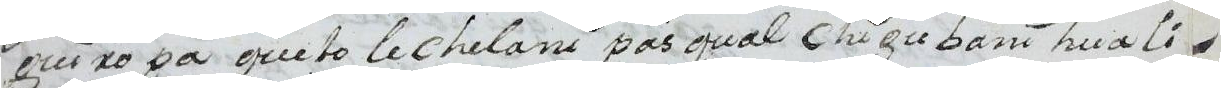

SDE725c (Zapotec)
  reference: guí xo pa que to le chelaní pas qual chígubaní huali
  model:     quiropa queto lechelani pasqual chi gabani huali



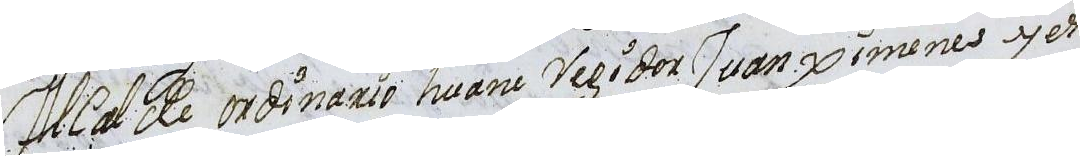

SDE726 (Zapotec)
  reference: Alcalde ordinaro huane regidor Juan ximenes y es
  model:     Alcalde ordinario huane regidor Juan ximenes y to



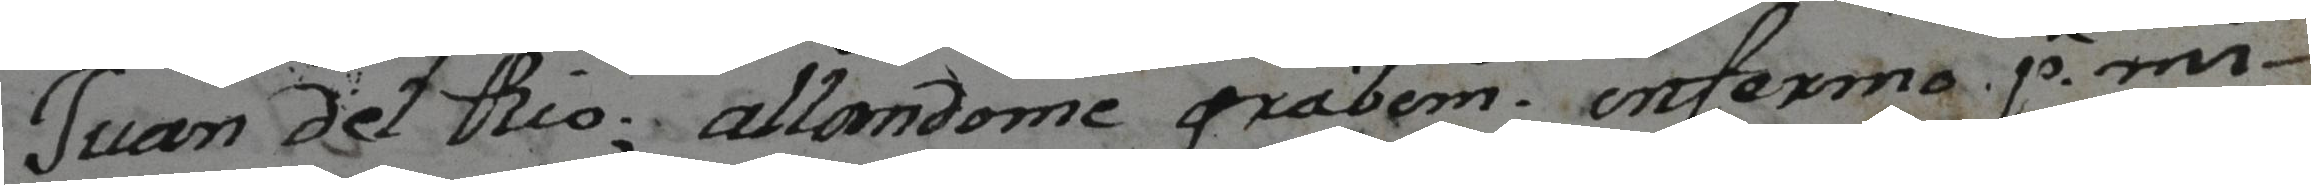

Ri832 (Spanish with some Zapotec)
  reference: Juan del Rio, allandome grabemte enforma pr mi
  model:     Juan del Rio. a la tome grabimto enfermo pr mi



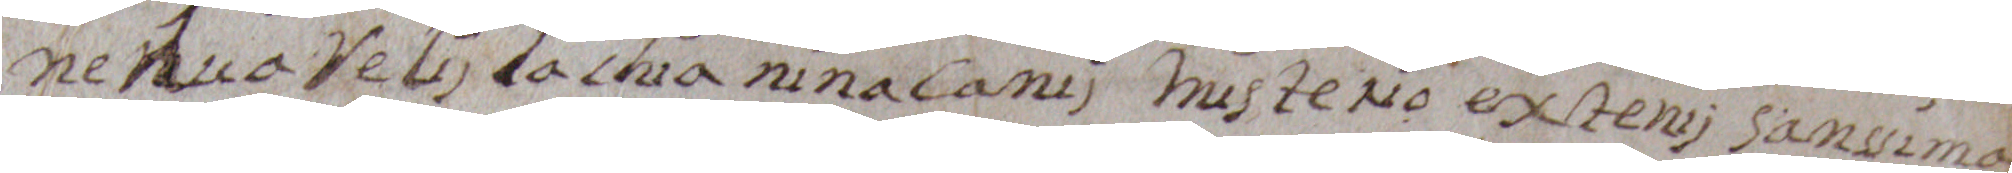

Ma733 (Zapotec)
  reference: ne hua relijlachia ni nacanij misterio extenij sanssima
  model:     ne huarielij lachia nina canij misterio estenij santisina



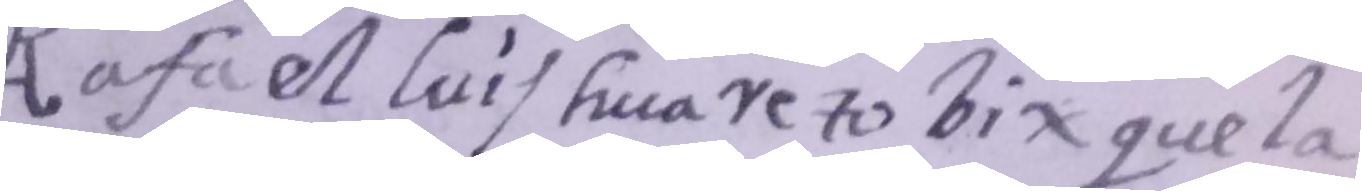

Al684 (Zapotec)
  reference: Rafael luis hua re tobix quela
  model:     defa el Luis hua reto bix quela



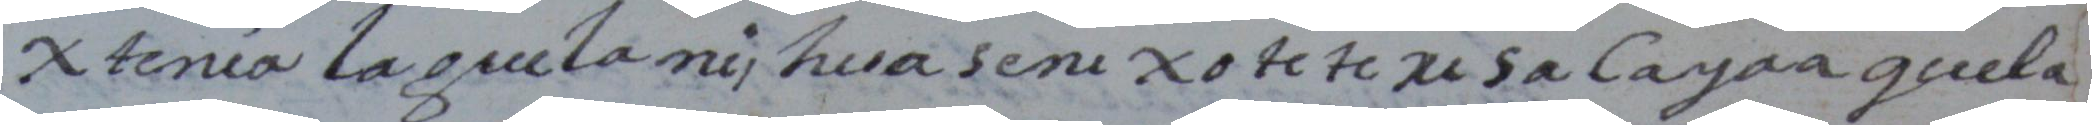

Tv758 (Zapotec)
  reference: xtenis laguelanij hua seni xotete risa cayaa quela
  model:     xtenia laguela nij hua seni xitete xi sacayaa quela



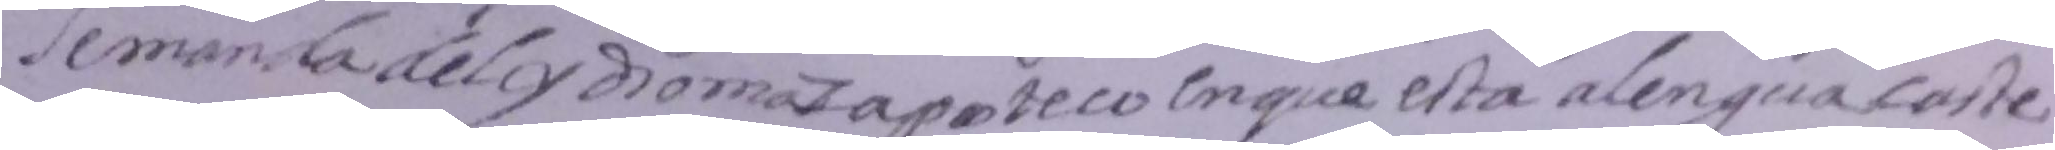

Al707T (Spanish)
  reference: se manda del ydioma zapoteco en que esta a lengua caste-
  model:     se manda del ydioma zapoteco en que esta a lengua caste

CER on these 8 lines: 10 beams 16.8%, with rerank 14.2%


In [5]:
images = [e['image'] for e in examples]
references = [e['reference'] for e in examples]
alone = reader.transcribe(images, rerank=False)
reranked = reader.transcribe(images)
for e, text in zip(examples, reranked):
    display(e['image'])
    print(f"{e['doc_id']} ({e['language']})\n  reference: {e['reference']}\n  model:     {text}\n")
print(f'CER on these {len(references)} lines: 10 beams {cer(references, [t or " " for t in alone]):.1%}, '
      f'with rerank {cer(references, [t or " " for t in reranked]):.1%}')

## 5. Your own images

Crop one text line per image, as tight as the dataset's line images (a little margin around the ink is fine), then:

```python
print(reader.transcribe('my_line.png'))
print(reader.transcribe(['line_1.png', 'line_2.png'], rerank=False))  # faster: one model, no rescoring
```

The model expects a single line in roughly the hands and spellings of 17th to 19th century Oaxacan documents. A whole page, several lines in one image, or printed text will read badly.